# 03 — Model Training & Selection

**Objective.** Benchmark a baseline plus a broad set of classifiers (linear, trees,
bagging, and four boosting libraries) under identical 5-fold stratified
cross-validation, then fit the winner on the full training split and persist a
single `Pipeline` (preprocessor + model) for serving.

Selection metric: **ROC-AUC**, with **churn recall** reported alongside as the
primary risk criterion. PR-AUC and F1 complete the picture for the imbalanced target.

In [1]:
import time, joblib, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from pathlib import Path
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").exists()), Path.cwd())
RAW = ROOT / "data" / "raw" / "binaryclassificationwithabankchurndataset"
PROC = ROOT / "data" / "processed"
MODELS = ROOT / "models"
FIG = MODELS / "figures"
for d in (PROC, FIG):
    d.mkdir(parents=True, exist_ok=True)
print("project root:", ROOT)

project root: /home/sabina/portfolio/creditscoring


In [2]:
train = pd.read_csv(PROC / "train.csv")
X = train.drop(columns=["Exited"]); y = train["Exited"]
num = X.select_dtypes(include=np.number).columns.tolist()
cat = X.select_dtypes(exclude=np.number).columns.tolist()

def make_preprocessor():
    return ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler())]), num),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat),
    ])

pos_weight = (y == 0).sum() / (y == 1).sum()
# Uniform preprocessor (one-hot for categoricals) is shared by every candidate.
# CatBoost still works on the numeric matrix; allow_writing_files=False prevents
# stray catboost_info/ scratch directories.
models = {
    "Dummy (prior)": DummyClassifier(strategy="prior"),
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=None,
                      class_weight="balanced_subsample", random_state=42, n_jobs=-1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=200, class_weight="balanced_subsample",
                      random_state=42, n_jobs=-1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(max_iter=200, learning_rate=0.06,
                      max_leaf_nodes=15, l2_regularization=1.0, random_state=42),
    "LightGBM": LGBMClassifier(n_estimators=300, num_leaves=15, learning_rate=0.05,
                      class_weight="balanced", verbose=-1, random_state=42, n_jobs=-1),
    "CatBoost": CatBoostClassifier(iterations=300, depth=5, learning_rate=0.05,
                      l2_leaf_reg=5, auto_class_weights="Balanced",
                      allow_writing_files=False, verbose=False,
                      random_state=42, thread_count=2),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                      subsample=0.8, colsample_bytree=0.8, scale_pos_weight=pos_weight,
                      eval_metric="logloss", random_state=42, n_jobs=-1, verbosity=0),
}
print("Models:", list(models))

Models: ['Dummy (prior)', 'Logistic Regression', 'Decision Tree', 'Random Forest', 'Extra Trees', 'Hist Gradient Boosting', 'LightGBM', 'CatBoost', 'XGBoost']


In [3]:
from sklearn.model_selection import StratifiedKFold, cross_validate
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision",
           "f1": "f1", "recall": "recall"}
rows = []
for name, est in models.items():
    pipe = Pipeline([("prep", make_preprocessor()), ("clf", est)])
    t0 = time.time()
    res = cross_validate(pipe, X, y, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({
        "model": name,
        "roc_auc": res["test_roc_auc"].mean(),
        "pr_auc": res["test_pr_auc"].mean(),
        "f1": res["test_f1"].mean(),
        "churn_recall": res["test_recall"].mean(),
        "fit_s": time.time() - t0,
    })
    print(f"{name:20s} done in {rows[-1]['fit_s']:.1f}s")

leaderboard = pd.DataFrame(rows).sort_values(
    ["roc_auc", "churn_recall"], ascending=False
).reset_index(drop=True)
leaderboard.round(4)

Dummy (prior)        done in 2.3s


Logistic Regression  done in 1.3s
Decision Tree        done in 0.2s


Random Forest        done in 2.3s


Extra Trees          done in 1.8s


Hist Gradient Boosting done in 0.8s


LightGBM             done in 503.3s


CatBoost             done in 1.9s


XGBoost              done in 2.1s


,model,roc_auc,pr_auc,f1,churn_recall,fit_s
0,CatBoost,0.9321,0.8095,0.7076,0.8451,1.8657
1,XGBoost,0.9301,0.8039,0.7080,0.8388,2.1139
2,Hist Gradient Boosting,0.9296,0.8022,0.7133,0.6625,0.7505
3,LightGBM,0.9279,0.7991,0.7091,0.8329,503.2727
4,Random Forest,0.9230,0.7782,0.6827,0.6033,2.2819
5,Extra Trees,0.9190,0.7675,0.6727,0.5982,1.8098
6,Decision Tree,0.9115,0.7583,0.6855,0.8426,0.1620
7,Logistic Regression,0.8838,0.6924,0.6393,0.8010,1.3458
8,Dummy (prior),0.5000,0.1985,0.0000,0.0000,2.2595


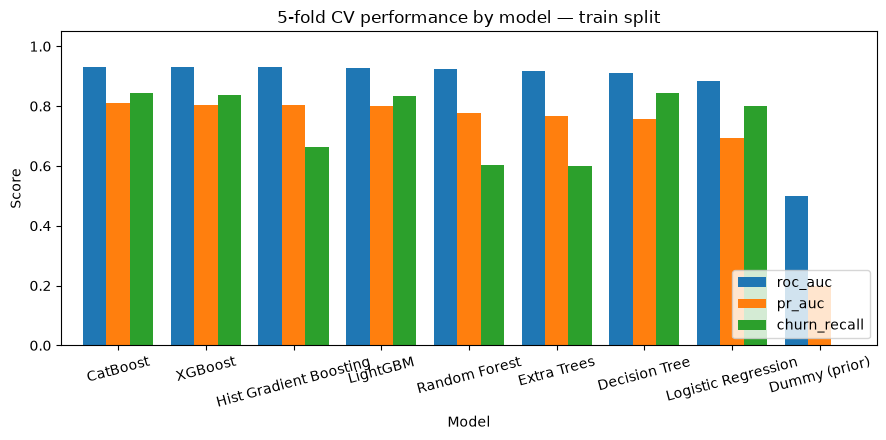

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.5))
plot_df = leaderboard.set_index("model")[["roc_auc", "pr_auc", "churn_recall"]]
plot_df.plot(kind="bar", ax=ax, width=0.8)
ax.set_title("5-fold CV performance by model — train split")
ax.set_xlabel("Model"); ax.set_ylabel("Score")
ax.set_ylim(0, 1.05); ax.legend(loc="lower right")
ax.tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

## Fit and persist the winner

The top model (excluding the dummy baseline) is refit on the entire training split.
Saving the **whole pipeline** — not just the estimator — locks preprocessing to the
exact fitted state used in training, eliminating train/serving skew.

In [5]:
best_name = leaderboard.loc[leaderboard["model"] != "Dummy (prior)", "model"].iloc[0]
best_est = models[best_name]
final_pipe = Pipeline([("prep", make_preprocessor()), ("clf", best_est)])
final_pipe.fit(X, y)
joblib.dump(final_pipe, MODELS / "pipeline.pkl")
leaderboard.to_csv(MODELS / "leaderboard.csv", index=False)
print("Selected model:", best_name)
print("Saved:", MODELS / "pipeline.pkl")

Selected model: CatBoost
Saved: /home/sabina/portfolio/creditscoring/models/pipeline.pkl


**Outcome.** Cross-validated leaderboard saved to `models/leaderboard.csv`; winning
pipeline saved to `models/pipeline.pkl`.

**Next:** 04_evaluation — a single held-out evaluation, explainability, and the
unlabelled test-set submission.